In [1]:
import numpy as np
import pandas as pd

df = pd.read_csv('opta-woman.csv')
df = df.rename({"Unnamed: 0" : "id"}, axis='columns')
df

,id,game_id,original_event_id,period_id,time_seconds,team_id,player_id,start_x,end_x,start_y,...,action_id,type_name,result_name,bodypart_name,scores,concedes,offensive_value,defensive_value,vaep_value,xT_value
0,0,2124863,2.208931e+09,1,1.0,9669,96521.0,52.605,73.395,34.000,...,0,pass,success,foot,0.003381,0.005883,0.000000,-0.000000,0.000000,0.005653
1,1,2124863,NaN,1,2.5,9669,421766.0,73.395,79.065,26.860,...,1,dribble,success,foot,0.003526,0.004914,0.000146,0.000969,0.001115,0.003425
2,2,2124863,2.208931e+09,1,4.0,9669,421766.0,79.065,79.590,24.140,...,2,pass,success,foot,0.008773,0.003995,0.005247,0.000919,0.006165,0.005623
3,3,2124863,2.208931e+09,1,9.0,9669,208367.0,78.645,85.890,46.920,...,3,pass,success,foot,0.004823,0.005999,-0.003950,-0.002004,-0.005955,0.030586
4,4,2124863,2.208932e+09,1,11.0,9669,132185.0,85.890,83.265,32.776,...,4,pass,success,foot,0.003761,0.001715,-0.001061,0.004284,0.003222,-0.024990
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10544,17196,2124874,2.210571e+09,2,2867.0,6272,112571.0,87.990,81.060,23.868,...,1372,pass,success,foot,0.003241,0.002361,-0.000848,-0.000697,-0.001545,0.005265
10545,17197,2124874,NaN,2,2870.0,6272,450242.0,81.060,72.450,35.224,...,1373,dribble,success,foot,0.002045,0.000850,-0.001196,0.001511,0.000315,-0.014492
10546,17198,2124874,2.210571e+09,2,2873.0,6272,450242.0,72.450,73.500,42.432,...,1374,pass,success,foot,0.004172,0.004006,0.002128,-0.003155,-0.001028,-0.003386
10547,17199,2124874,2.210571e+09,2,2876.0,6272,205854.0,73.500,38.220,62.764,...,1375,pass,success,foot,0.004835,0.001416,0.000663,0.002590,0.003252,0.000875


In [2]:
df = df.loc[df['game_id'] == 2124863]
df = df.sort_values(by=['action_id'])
df = df.reset_index()
df

,index,id,game_id,original_event_id,period_id,time_seconds,team_id,player_id,start_x,end_x,...,action_id,type_name,result_name,bodypart_name,scores,concedes,offensive_value,defensive_value,vaep_value,xT_value
0,0,0,2124863,2.208931e+09,1,1.0,9669,96521.0,52.605,73.395,...,0,pass,success,foot,0.003381,0.005883,0.000000,-0.000000,0.000000,0.005653
1,1,1,2124863,NaN,1,2.5,9669,421766.0,73.395,79.065,...,1,dribble,success,foot,0.003526,0.004914,0.000146,0.000969,0.001115,0.003425
2,2,2,2124863,2.208931e+09,1,4.0,9669,421766.0,79.065,79.590,...,2,pass,success,foot,0.008773,0.003995,0.005247,0.000919,0.006165,0.005623
3,3,3,2124863,2.208931e+09,1,9.0,9669,208367.0,78.645,85.890,...,3,pass,success,foot,0.004823,0.005999,-0.003950,-0.002004,-0.005955,0.030586
4,4,4,2124863,2.208932e+09,1,11.0,9669,132185.0,85.890,83.265,...,4,pass,success,foot,0.003761,0.001715,-0.001061,0.004284,0.003222,-0.024990
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
909,909,1451,2124863,NaN,2,2868.0,9669,174330.0,21.840,19.740,...,1451,dribble,success,foot,0.010145,0.000508,0.007939,-0.000176,0.007763,0.000000
910,910,1453,2124863,2.208950e+09,2,2870.0,6272,450242.0,27.510,24.255,...,1453,pass,success,foot,0.021996,0.001878,0.021034,0.003523,0.024557,0.005858
911,911,1454,2124863,2.208950e+09,2,2872.0,6272,153890.0,24.255,35.910,...,1454,pass,success,foot,0.047996,0.002848,0.026000,-0.000971,0.025029,-0.006107
912,912,1455,2124863,2.208950e+09,2,2873.0,6272,209831.0,35.910,35.910,...,1455,pass,success,foot,0.033431,0.003376,-0.014565,-0.000527,-0.015093,-0.001483


In [3]:
def get_sequences_opta(df):
    sequences = []
    sequence = []
    prev_team = df['team_id'][0]
    for _, row in df.iterrows():
        if row['team_id'] != prev_team:
            sequences.append(pd.DataFrame(sequence))
            sequence = []
        sequence.append(row)
        prev_team = row['team_id']
    return sequences

In [4]:
sequences = get_sequences_opta(df)
sequences[0]

,index,id,game_id,original_event_id,period_id,time_seconds,team_id,player_id,start_x,end_x,...,action_id,type_name,result_name,bodypart_name,scores,concedes,offensive_value,defensive_value,vaep_value,xT_value
0,0,0,2124863,2.208931e+09,1,1.0,9669,96521.0,52.605,73.395,...,0,pass,success,foot,0.003381,0.005883,0.000000,-0.000000,0.000000,0.005653
1,1,1,2124863,NaN,1,2.5,9669,421766.0,73.395,79.065,...,1,dribble,success,foot,0.003526,0.004914,0.000146,0.000969,0.001115,0.003425
2,2,2,2124863,2.208931e+09,1,4.0,9669,421766.0,79.065,79.590,...,2,pass,success,foot,0.008773,0.003995,0.005247,0.000919,0.006165,0.005623
3,3,3,2124863,2.208931e+09,1,9.0,9669,208367.0,78.645,85.890,...,3,pass,success,foot,0.004823,0.005999,-0.003950,-0.002004,-0.005955,0.030586
4,4,4,2124863,2.208932e+09,1,11.0,9669,132185.0,85.890,83.265,...,4,pass,success,foot,0.003761,0.001715,-0.001061,0.004284,0.003222,-0.024990
5,5,5,2124863,NaN,1,13.5,9669,421766.0,83.265,72.975,...,5,dribble,success,foot,0.008639,0.002426,0.004878,-0.000711,0.004167,-0.006592
6,6,6,2124863,2.208932e+09,1,16.0,9669,421766.0,72.975,54.705,...,6,pass,success,foot,0.010806,0.000190,0.002166,0.002236,0.004402,-0.002366
7,7,7,2124863,NaN,1,17.0,9669,132503.0,54.705,49.245,...,7,dribble,success,foot,0.007278,0.000334,-0.003528,-0.000143,-0.003671,0.000477


In [5]:
sequences[1]

,index,id,game_id,original_event_id,period_id,time_seconds,team_id,player_id,start_x,end_x,...,action_id,type_name,result_name,bodypart_name,scores,concedes,offensive_value,defensive_value,vaep_value,xT_value
8,8,9,2124863,2.208932e+09,1,22.0,6272,209831.0,36.225,7.770,...,9,pass,success,foot,0.001445,0.007640,-0.000005,-0.000666,-0.000671,0.048120
9,9,10,2124863,NaN,1,23.5,6272,174571.0,7.770,14.490,...,10,dribble,success,foot,0.000828,0.007295,-0.000617,0.000346,-0.000271,-0.040774
10,10,11,2124863,2.208932e+09,1,25.0,6272,174571.0,14.490,29.820,...,11,pass,success,foot,0.002999,0.006763,0.002171,0.000532,0.002703,-0.005935
11,11,12,2124863,NaN,1,26.5,6272,165678.0,29.820,35.175,...,12,dribble,success,foot,0.009003,0.001020,0.006003,0.005743,0.011746,-0.002869
12,12,13,2124863,2.208932e+09,1,28.0,6272,165678.0,35.175,50.820,...,13,pass,success,foot,0.008134,0.000239,-0.000869,0.000781,-0.000088,-0.002430
13,13,14,2124863,NaN,1,29.5,6272,96373.0,50.820,56.910,...,14,dribble,success,foot,0.007278,0.000334,-0.000856,-0.000095,-0.000951,-0.000977


In [6]:
sequences[2]

,index,id,game_id,original_event_id,period_id,time_seconds,team_id,player_id,start_x,end_x,...,action_id,type_name,result_name,bodypart_name,scores,concedes,offensive_value,defensive_value,vaep_value,xT_value
14,14,16,2124863,2.208932e+09,1,35.0,9669,114407.0,63.735,88.725,...,16,pass,success,foot,0.002995,0.006241,0.002414,-0.003594,-0.001180,0.008162
15,15,17,2124863,2.208932e+09,1,39.0,9669,132185.0,90.510,79.590,...,17,pass,success,foot,0.008701,0.001769,0.005706,0.004472,0.010178,-0.004833
16,16,18,2124863,NaN,1,40.0,9669,208367.0,79.590,76.335,...,18,dribble,success,foot,0.002815,0.001284,-0.005886,0.000485,-0.005401,-0.000264
17,17,19,2124863,2.208932e+09,1,41.0,9669,208367.0,76.335,74.550,...,19,pass,success,foot,0.008469,0.003568,0.005654,-0.002285,0.003369,0.001946
18,18,20,2124863,2.208932e+09,1,42.0,9669,114407.0,71.820,74.970,...,20,pass,success,foot,0.007221,0.004522,-0.001248,-0.000954,-0.002201,0.004402
19,19,21,2124863,2.208932e+09,1,47.0,9669,421766.0,73.290,88.620,...,21,pass,success,foot,0.004150,0.003364,-0.003071,0.001159,-0.001913,0.002956
20,20,22,2124863,2.208932e+09,1,51.0,9669,132185.0,85.890,80.535,...,22,pass,success,foot,0.001675,0.001210,-0.002475,0.002154,-0.000321,-0.003025
21,21,23,2124863,NaN,1,52.0,9669,114407.0,80.535,81.480,...,23,dribble,success,foot,0.002694,0.005075,0.001019,-0.003865,-0.002846,0.000000
22,22,24,2124863,2.208932e+09,1,53.0,9669,114407.0,81.480,78.120,...,24,pass,success,foot,0.005585,0.001899,0.002891,0.003176,0.006067,-0.004584


In [7]:
import matplotlib.pyplot as plt

def draw_pitch(ax, x_areas=12, y_areas=8, scale=1):
    # size of the pitch is 120, 80
    X = ['A','B','C','D','E','F','G','H','I','J','K','L','M','N','O','P','Q','R','S','T']
    Y = [i+1 for i in range(20)]

    #Pitch Outline & Centre Line
    plt.plot([0,0],[0,80*scale], color="black")
    plt.plot([0,120*scale],[80*scale,80*scale], color="black")
    plt.plot([120*scale,120*scale],[80*scale,0], color="black")
    plt.plot([120*scale,0],[0,0], color="black")
    plt.plot([60*scale,60*scale],[0,80*scale], color="black")
    
    for i in range (0,x_areas):
        plt.text((((60/x_areas)+i*120/x_areas)-1)*scale, 82*scale, str(X[i]), fontsize=8*scale)

    for i in range (0,y_areas):
        plt.text(-3*scale, (80 * scale) - (5.5 * scale) - (i * 10 * scale), str(Y[i]), fontsize=8*scale)

    # Left Penalty Area
    plt.plot([14.6*scale,14.6*scale],[57.8*scale,22.2*scale],color="black")
    plt.plot([0,14.6*scale],[57.8*scale,57.8*scale],color="black")
    plt.plot([0,14.6*scale],[22.2*scale,22.2*scale],color="black")

    # Right Penalty Area
    plt.plot([120*scale,105.4*scale],[57.8*scale,57.8*scale],color="black")
    plt.plot([105.4*scale,105.4*scale],[57.8*scale,22.5*scale],color="black")
    plt.plot([120*scale, 105.4*scale],[22.5*scale,22.5*scale],color="black")

    # Left 6-yard Box
    plt.plot([0,4.9*scale],[48*scale,48*scale],color="black")
    plt.plot([4.9*scale,4.9*scale],[48*scale,32*scale],color="black")
    plt.plot([0,4.9*scale],[32*scale,32*scale],color="black")

    # Right 6-yard Box
    plt.plot([120*scale,115.1*scale],[48*scale,48*scale],color="black")
    plt.plot([115.1*scale,115.1*scale],[48*scale,32*scale],color="black")
    plt.plot([120*scale,115.1*scale],[32*scale,32*scale],color="black")
    
    # Sectors
    for i in range(1, y_areas):
        plt.plot([120*scale,0],[(80/y_areas)*i*scale,(80/y_areas)*i*scale], color="gray")

    for i in range(1, x_areas):
        plt.plot([(120/x_areas)*i*scale,(120/x_areas)*i*scale],[80*scale,0], color="gray")
    
    # Prepare Circles
    centreCircle = plt.Circle((60*scale,40*scale),8.1*scale,color="black",fill=False)  # type: ignore
    centreSpot = plt.Circle((60*scale,40*scale),0.71,color="black") # type: ignore
    leftPenSpot = plt.Circle((9.7*scale,40*scale),0.71,color="black") # type: ignore
    rightPenSpot = plt.Circle((110.3*scale,40*scale),0.71,color="black") # type: ignore

    # Draw Circles
    ax.add_patch(centreCircle)
    ax.add_patch(centreSpot)
    ax.add_patch(leftPenSpot)
    ax.add_patch(rightPenSpot)

def draw_events_sequence(sequence, start_team, x_areas=12, y_areas=8, scale=1):
    if x_areas < 2:
        x_areas = 2
    if y_areas < 2:
        y_areas = 2
    if scale < 1:
        scale = 1
    fig, ax = plt.subplots()
    fig.set_size_inches(7*scale, 5*scale)
    i = 0
    team = [team for team in sequence['team_id']][0]
    player = ''
    
    print(f'Team: {team}')

    for _, row in sequence.iterrows():
        if player != row['player_id']:
            player = row['player_id']
            i+=1
        event_type = row['type_name']
        timespamp = row['time_seconds']
        print(f'{i}: {player} ({event_type}) <{timespamp}>')
        if row['team_id'] == start_team:
            general_color = 'blue'
        else:
            general_color = 'red'
        start = (float(row['start_x']*scale), float(row['start_y']*scale))
        if row['end_x'] != '' and row['end_y'] != '':
            end = (float(row['end_x']*scale), float(row['end_y']*scale))
        else:
            end = start
        match row['type_name']:
            case 'pass':
                plt.plot([start[0], end[0]], [start[1], end[1]], color=general_color, linewidth=scale)
                plt.plot(start[0], start[1], marker='o', markersize=8*scale, markeredgecolor=general_color, markerfacecolor="black")
            case 'dribble':
                plt.plot(start[0], start[1], marker='s', markersize=8*scale, markeredgecolor=general_color, markerfacecolor="black")
                plt.plot([start[0], end[0]], [start[1], end[1]], color='green', linewidth=scale)
            case _:
                plt.plot(start[0], start[1], marker='1', markersize=8*scale, markeredgecolor=general_color, markerfacecolor="black")
        plt.text(start[0]-(scale/2), start[1]-(scale/2), str(i), color='white', fontsize=4*scale)

    draw_pitch(ax, x_areas, y_areas, scale)
    plt.show()

sequence 0
Team: 9669
1: 96521.0 (pass) <1.0>
2: 421766.0 (dribble) <2.5>
2: 421766.0 (pass) <4.0>
3: 208367.0 (pass) <9.0>
4: 132185.0 (pass) <11.0>
5: 421766.0 (dribble) <13.5>
5: 421766.0 (pass) <16.0>
6: 132503.0 (dribble) <17.0>


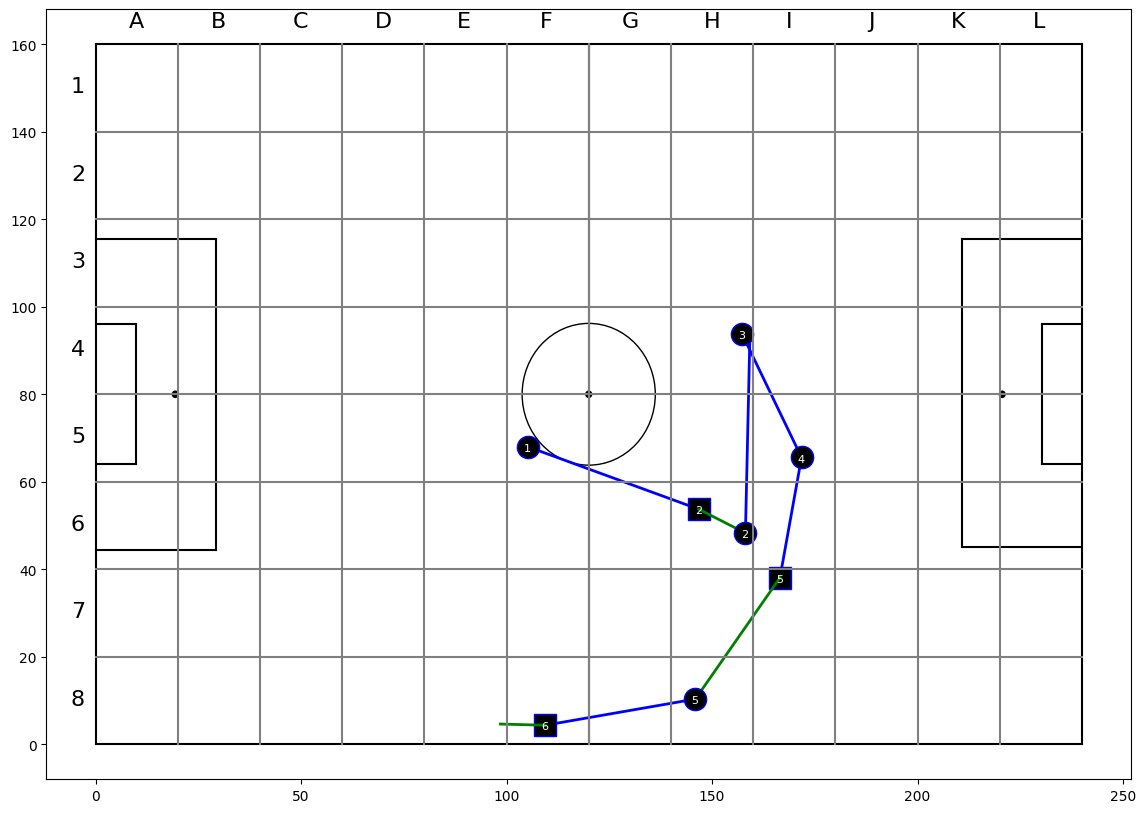

sequence 1
Team: 6272
1: 209831.0 (pass) <22.0>
2: 174571.0 (dribble) <23.5>
2: 174571.0 (pass) <25.0>
3: 165678.0 (dribble) <26.5>
3: 165678.0 (pass) <28.0>
4: 96373.0 (dribble) <29.5>


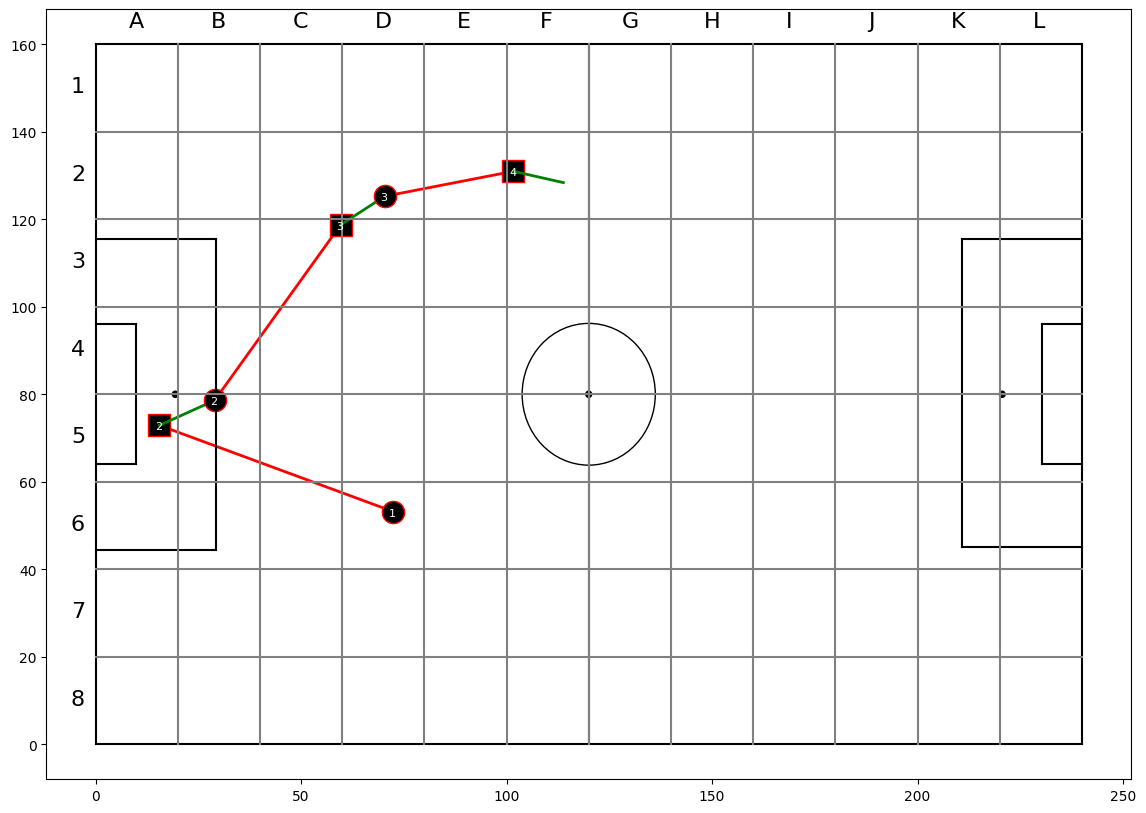

sequence 2
Team: 9669
1: 114407.0 (pass) <35.0>
2: 132185.0 (pass) <39.0>
3: 208367.0 (dribble) <40.0>
3: 208367.0 (pass) <41.0>
4: 114407.0 (pass) <42.0>
5: 421766.0 (pass) <47.0>
6: 132185.0 (pass) <51.0>
7: 114407.0 (dribble) <52.0>
7: 114407.0 (pass) <53.0>


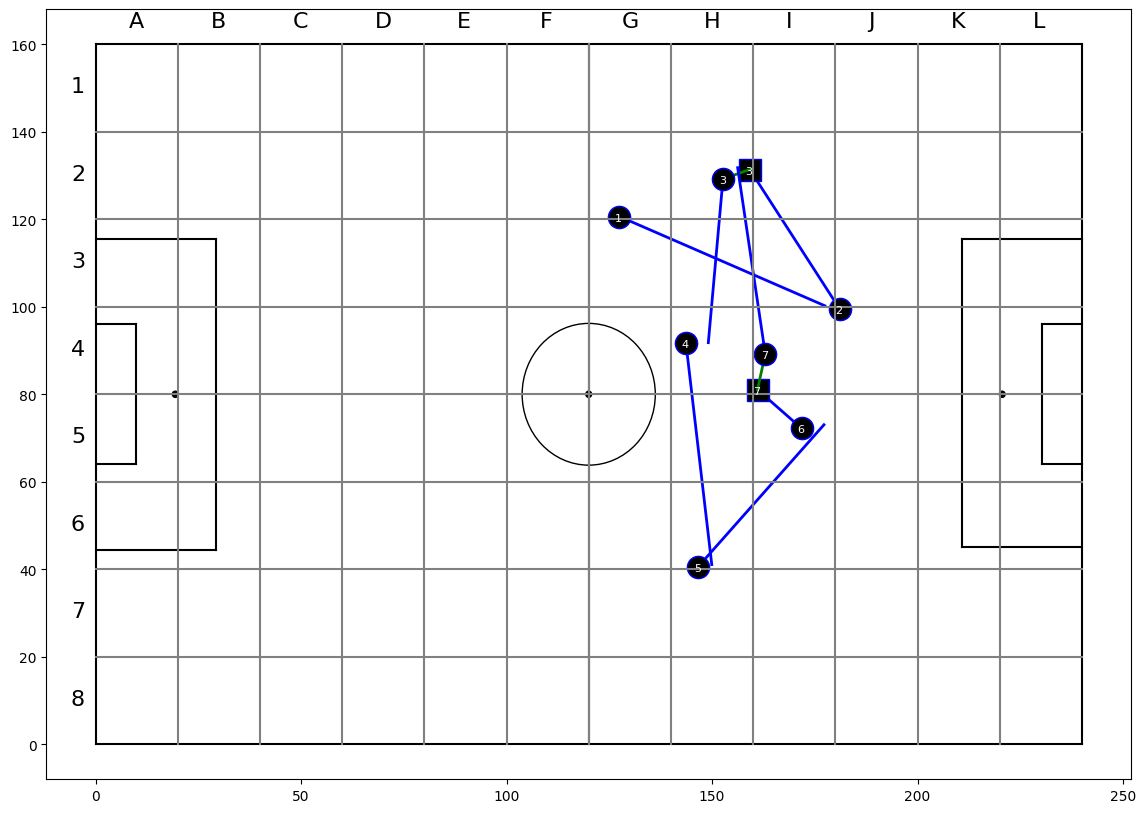

sequence 3
Team: 6272
1: 174345.0 (pass) <60.0>
2: 209831.0 (pass) <62.0>
3: 112571.0 (pass) <64.0>
4: 205854.0 (dribble) <66.0>
4: 205854.0 (pass) <68.0>
5: 174571.0 (pass) <70.0>
6: 112571.0 (pass) <73.0>
7: 165678.0 (pass) <76.0>


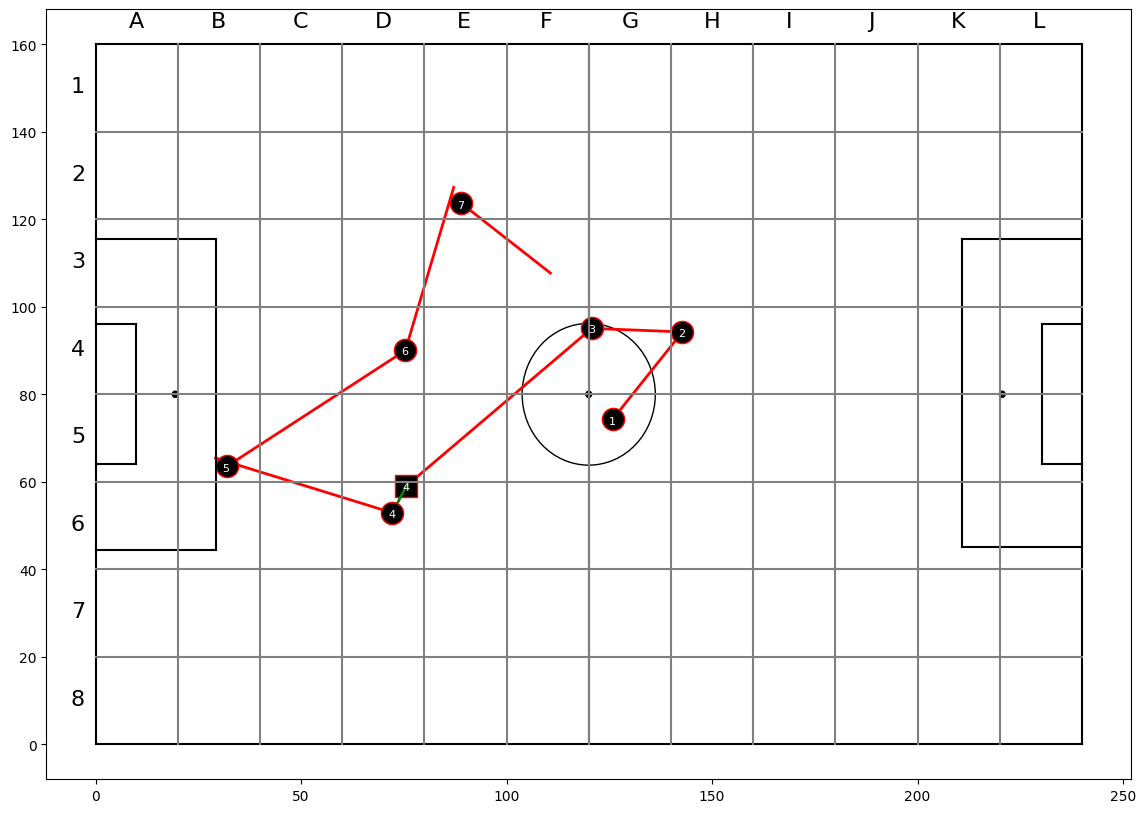

sequence 4
Team: 9669
1: 114407.0 (dribble) <107.0>
1: 114407.0 (pass) <108.0>
2: 107957.0 (pass) <109.0>
3: 114407.0 (pass) <111.0>
4: 132185.0 (dribble) <112.5>
5: 132503.0 (dribble) <116.0>
5: 132503.0 (dribble) <118.5>
5: 132503.0 (pass) <119.0>


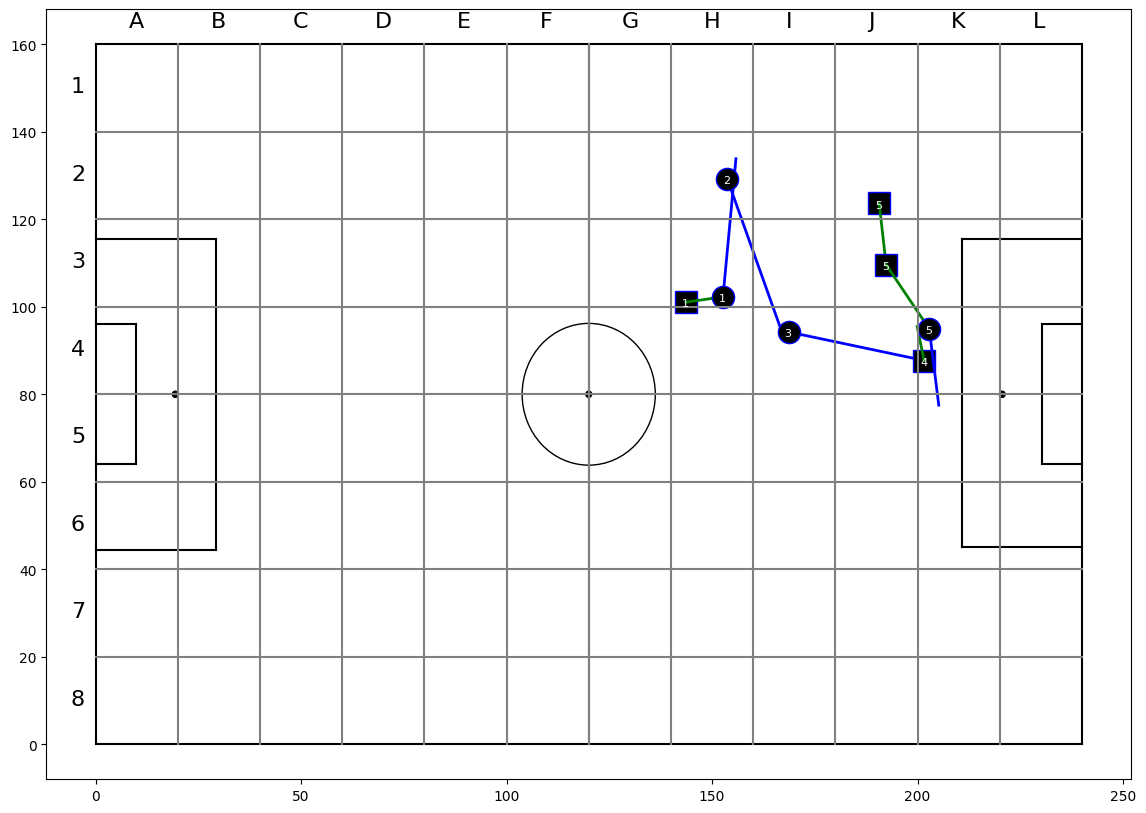

In [8]:
start_team = df['team_id'][0]

for i, s in enumerate(sequences):
    print(f'sequence {i}')
    draw_events_sequence(s, start_team, 12, 8, scale=2)
    if i == 4:
        break

In [24]:
def get_event_locations(df, event, place, result, team=None):
    df_event = df.loc[df['type_name'] == event]
    df_event = df_event.loc[df['team_id'] == team]
    df_event = df_event.loc[df['result_name'] == result]
    location = [[x, y] for x,y in zip(df_event[f'{place}_x'].values, df_event[f'{place}_y'].values)]
    df_event['location'] = location
    location_xy = df_event.location.apply(pd.Series)
    location_xy.columns = ['x', 'y']
    return location_xy

In [25]:
location_xy = get_event_locations(df, 'pass', 'start', 'success', start_team)
location_xy.head(5)

,x,y
0,52.605,34.000
2,79.065,24.140
3,78.645,46.920
4,85.890,32.776
6,72.975,5.168


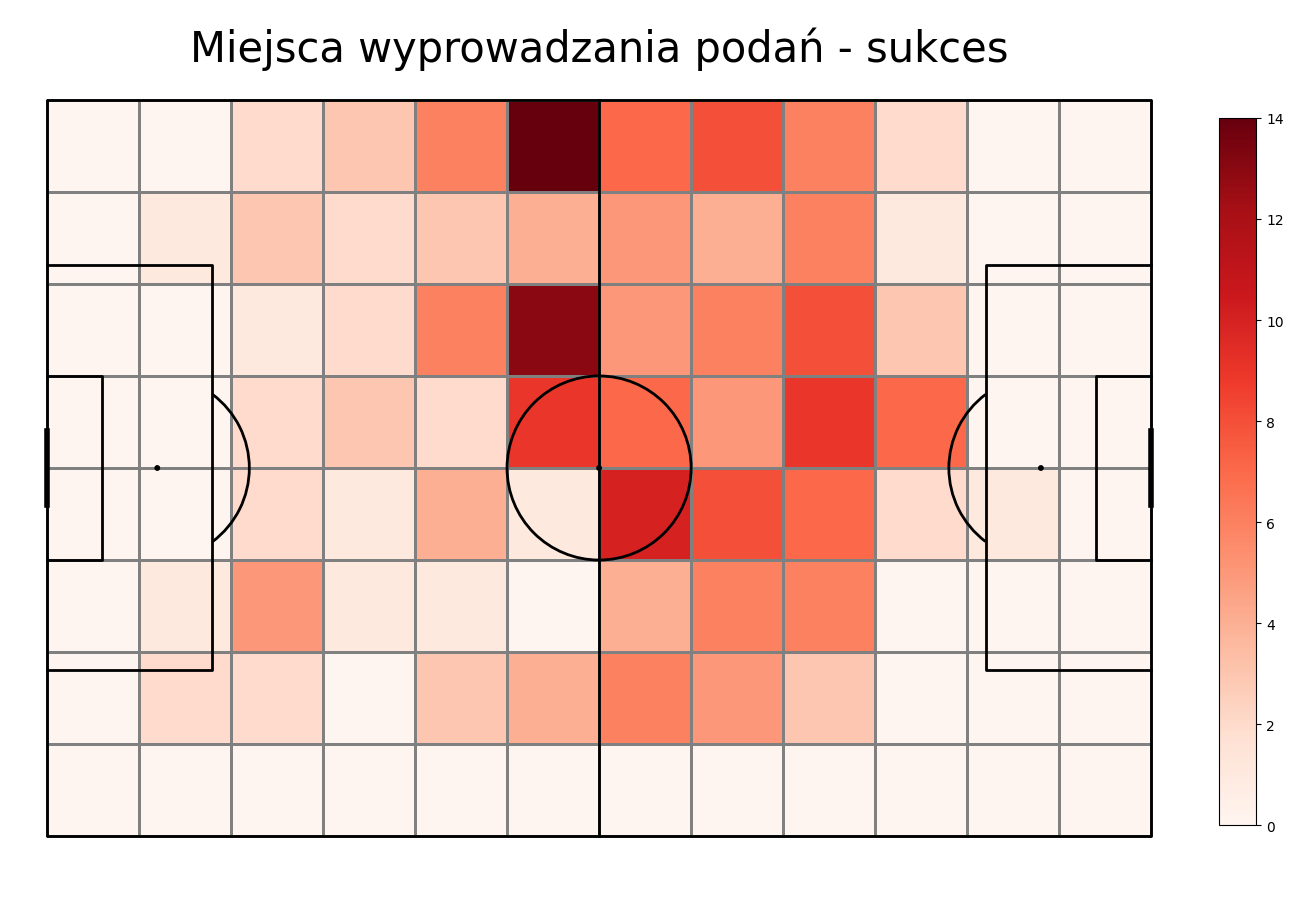

In [26]:
from draw.draw_heatmap import draw_heatmap

draw_heatmap(location_xy=location_xy, title='Miejsca wyprowadzania podań - sukces', x_areas=12, y_areas=8)

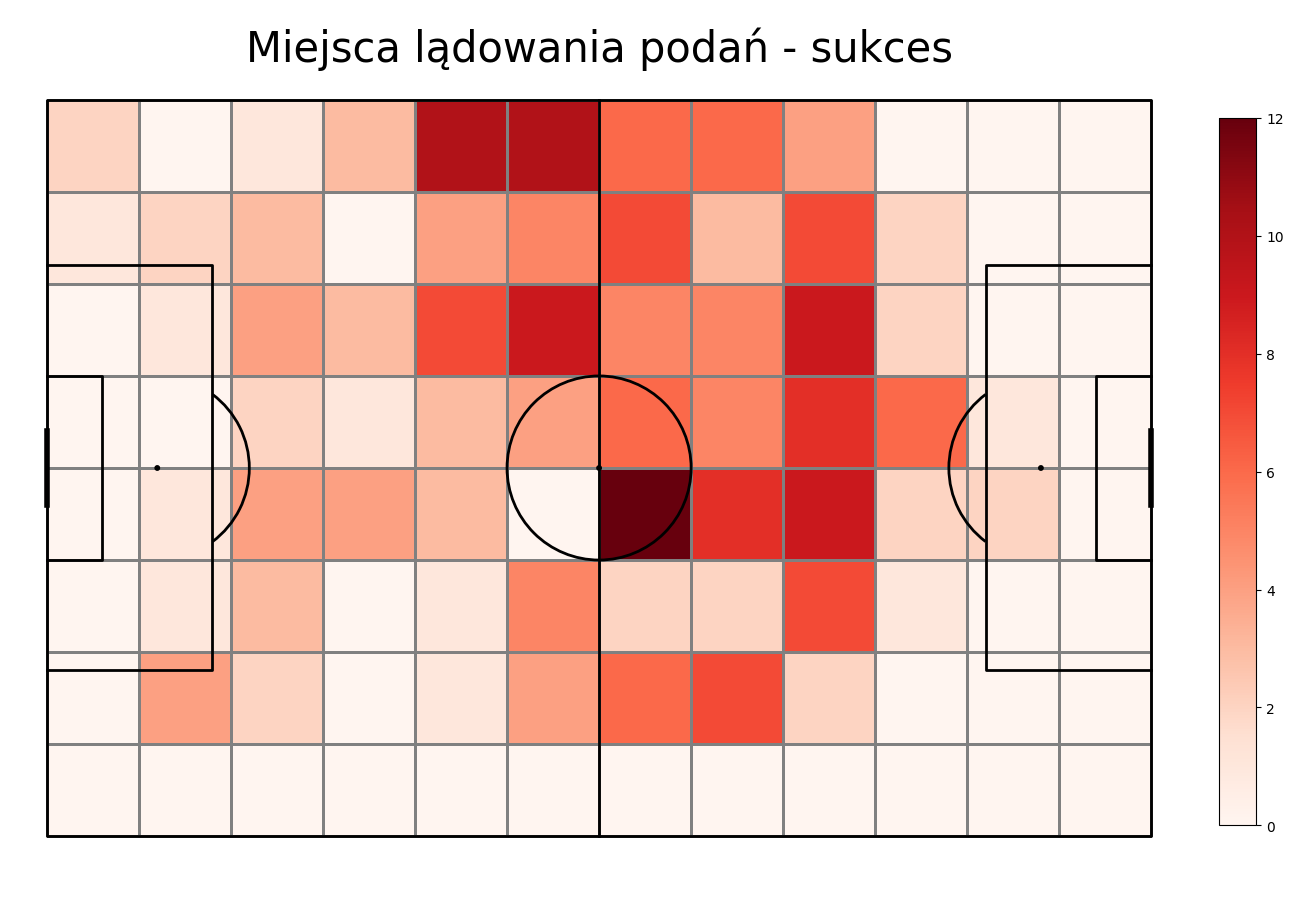

In [28]:
location_xy = get_event_locations(df, 'pass', 'end', 'success', start_team)
draw_heatmap(location_xy=location_xy, title='Miejsca lądowania podań - sukces', x_areas=12, y_areas=8)

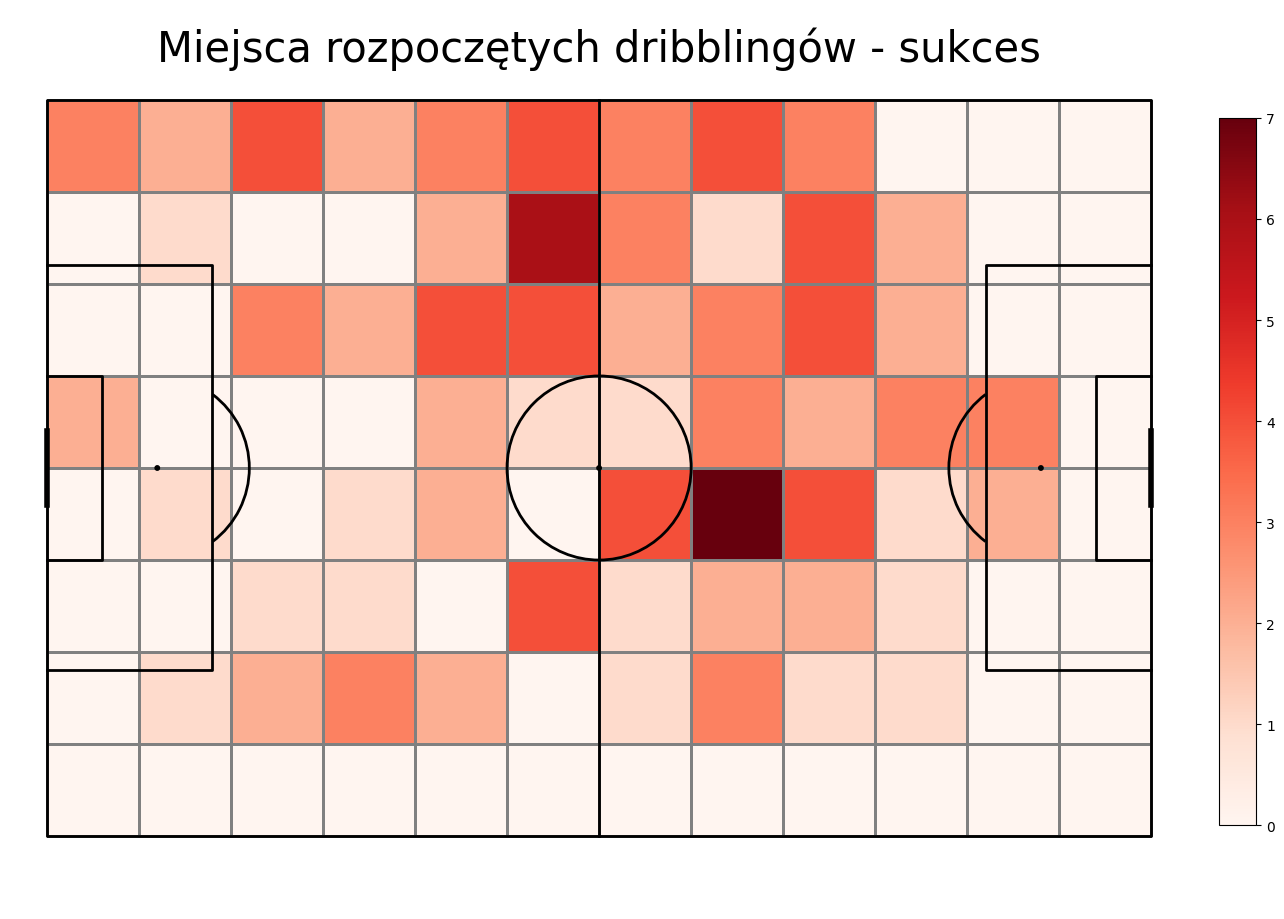

In [29]:
location_xy = get_event_locations(df, 'dribble', 'start', 'success', start_team)
draw_heatmap(location_xy=location_xy, title='Miejsca rozpoczętych dribblingów - sukces', x_areas=12, y_areas=8)

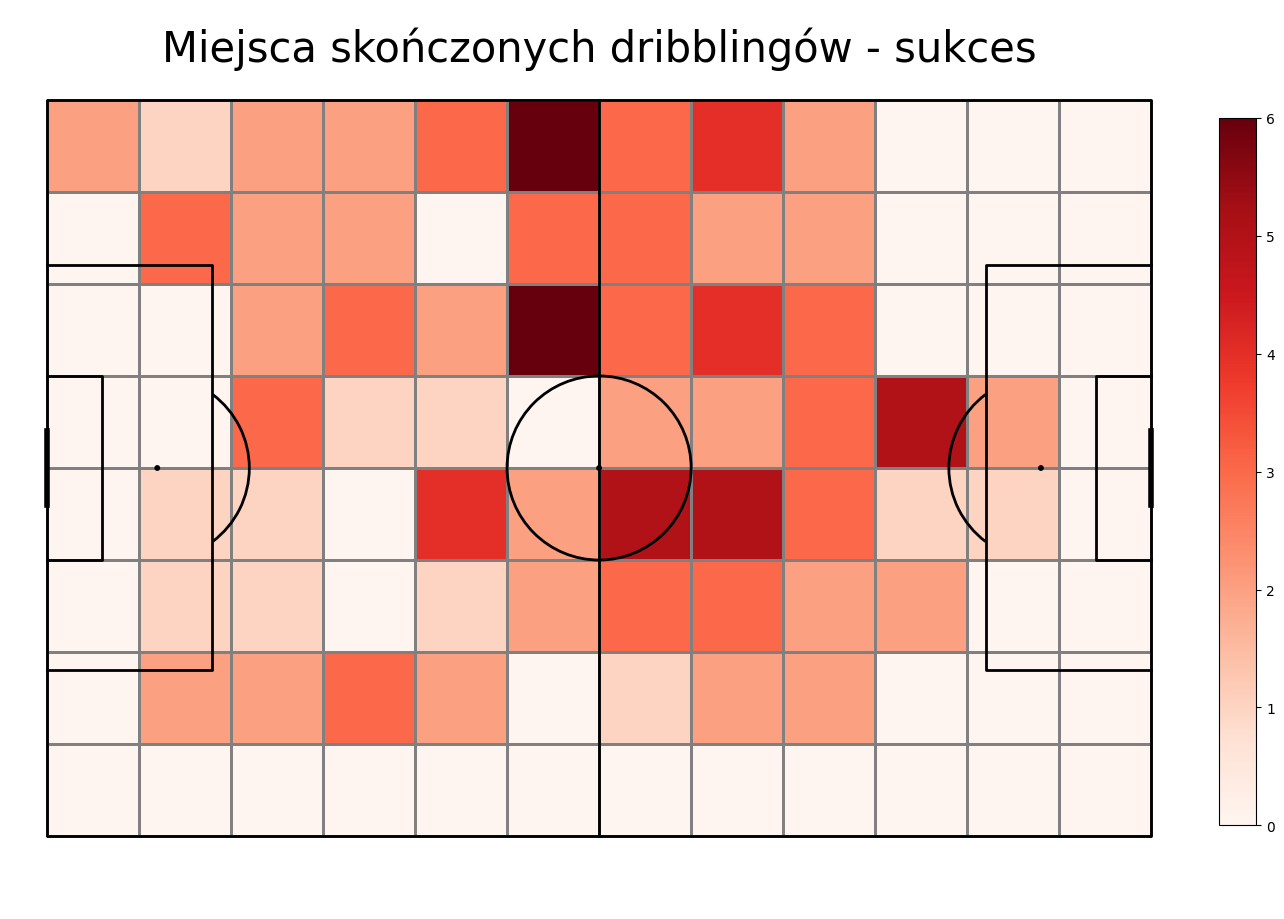

In [30]:
location_xy = get_event_locations(df, 'dribble', 'end', 'success', start_team)
draw_heatmap(location_xy=location_xy, title='Miejsca skończonych dribblingów - sukces', x_areas=12, y_areas=8)